# 10 — The advisor and the decision gym: AI inside the decision, scored against outcomes

An LLM advisor that sees only the result tables of notebooks 07–09 recommends a book for the base case and each named stress, explains it with numbers the tables hold (a mechanical check counts every number it writes), argues against the human's stated preference in two rounds (the motivated-reasoning check and the opposing case), and is scored in a decision gym: sixteen documented past situations built as of their date with no hindsight — queue requests at entry and at the two-year gate in three regions, the lease candidates at the start of the 2014, 2020 and 2022 oil-price regimes, a 2018 budget cut — in which instinct (top-N NPV), the registered optimizer rule, the advisor and the human each pick a book under the same budget and the realized value is then revealed. A forward view values every candidate within 1, 2, 3, 5, 10 and 20 years and names the book at each horizon. Every API call is recorded to `results/advisor_runs.jsonl` and replayed from there, so this notebook runs offline; without a key and without a record, the advisor's rows read "not recorded" and nothing else changes (PLAN.md §14.10 and its addenda).

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/candidate_npv.csv`, `results/stress_candidates.csv`, `results/stress_tests.csv`, `results/portfolio_books.csv`, `results/portfolio_scores.csv`, `results/portfolio_allocation.csv`, `results/project_impact.csv`, `results/decision_ledger.csv`, `results/success_criteria_v7_registered.json` | notebooks 07–09: the only facts the advisor sees |
| in | `results/decision_pack.csv` | notebook 09 part B: the queue requests as of entry and the two-year gate, with their realized status |
| in | `data/interim/upstream_monthly.parquet`, `data/interim/market_monthly.parquet`, `data/interim/cpi_monthly.parquet`, `data/raw/prices/RWTCm.xls`, `RNGWHHDm.xls` | the lease histories and the price regimes |
| in | `data/processed/predictions_landmark.parquet`, `data/processed/predictions_v2.parquet`, `data/processed/candidate_npv_scenarios.parquet` | the operation curves and the held-out scenarios |
| in | `prompts/*.md`; `.env` (`ANTHROPIC_API_KEY`, never printed) or the `claude` command signed in to the Claude subscription | the prompt templates; the backend, if one is available |
| out | `results/advisor_runs.jsonl` | every call: prompts, model, parameters, response, usage, verification (the replay record) |
| out | `results/advisor_recommendations.csv`, `results/advisor_transcripts/*.md` | the recommendation per scenario and per horizon; the challenge transcripts |
| out | `results/decision_gym_situations.csv`, `results/decision_gym_scores.csv` | the sixteen situations and one score per actor per situation |
| out | `results/horizon_view.csv`, `results/horizon_books.csv` | every candidate within each horizon; the book at each horizon |
| out | `results/advisor_evaluation.csv`, `results/advisor_rubric.csv`, `results/decision_ledger.csv` (appended) | the evaluation of the AI outputs; the ledger |
| out | `figures/F34_decision_gym.*`, `figures/F35_horizon_view.*` | the pictures |

*Execution order:* runs last, after notebook 09 (and 06).

## Setup

In [1]:
import json
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import advisor as adv, config, decision_date, economics as ec, energy_data, gym, horizons as hz, optimizer as opt, paths, plots, scenarios as sc

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "10_advisor_and_gym"
START = time.time()
R = paths.RESULTS
TRANSCRIPTS = R / "advisor_transcripts"
TRANSCRIPTS.mkdir(exist_ok=True)
registered = json.loads((R / "success_criteria_v7_registered.json").read_text(encoding="utf-8"))
LAM, LEVEL, CAP = registered["lam"], registered["level"], registered.get("technology_cap", 0.4)
ledger = pd.read_csv(R / "decision_ledger.csv")
BUDGET = float(ledger.loc[0, "budget"])  # the registered budget of notebook 09 (40% of the default book's capital)
CASE = "contracted"
advisor = adv.Advisor(mode="auto")  # live through the API key or the claude command when one is available, replay otherwise; every call is recorded
print(f"advisor: model {advisor.model}, {f'live ({advisor.backend})' if advisor.live else 'replay only (no backend)'}, {len(advisor.records)} recorded calls; budget ${BUDGET / 1e9:.2f}B, cap {CAP:.0%}")


advisor: model claude-sonnet-5-5, live (cli), 331 recorded calls; budget $2.31B, cap 40%


## 1. The grounding: what the advisor is allowed to know

The advisor's context is a handful of result tables rendered as text with one number formatter, and the check in `advisor.verify_numbers` accepts a number in an answer only if the same token appears in that text. The tables: the forty candidates (capital, expected NPV merchant and contracted, the NPV under the scenario in question, P(operation within 7 years), break-even, data completeness, provenance), the six books with their out-of-sample scores and members, the capital by technology, and the named stresses. The system prompt (`prompts/advisor_system.md`) states the rule; the templates of the three modes are printed below the tables so the appendix carries the actual prompts.

In [2]:
cand = pd.read_csv(R / "candidate_npv.csv")
ids = list(cand["project_id"])
books = pd.read_csv(R / "portfolio_books.csv", index_col=0)
BOOK_NAMES = [c for c in books.columns if c not in ("technology", "capex")]
scores = pd.read_csv(R / "portfolio_scores.csv")
oos = scores[scores["scenarios"].str.startswith("held-out") & (scores["revenue_case"] == CASE)].set_index("book")
stresses = pd.read_csv(R / "stress_tests.csv")
stress_c = pd.read_csv(R / "stress_candidates.csv")
alloc = pd.read_csv(R / "portfolio_allocation.csv")
impact = pd.read_csv(R / "project_impact.csv")
scen = pd.read_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet")
A_copula = scen[(scen["generator"] == "copula") & (scen["revenue_case"] == CASE)].sort_values("scenario")[ids].to_numpy(float)
capex = cand.set_index("project_id")["stage1_charge"]  # what one budget dollar buys now (decision #90); full capital stays in cand["capex"]
x_D = books["D risk-aware MILP"].reindex(ids).to_numpy(int)


def candidate_table(stress="base"):  # kept for the gym and the forward view; the advisor's DATA block comes from adv.portfolio_context
    """The forty candidates with their NPV under one named stress, in $ million."""
    npv_stress = stress_c[stress_c["stress"] == stress].set_index("project_id")["npv"]
    t = pd.DataFrame({"project_id": cand["project_id"], "technology": cand["technology"], "capex_$M": cand["capex"] / 1e6,
                      "expected_npv_merchant_$M": cand["expected_npv_base"] / 1e6, "expected_npv_contracted_$M": cand["expected_npv_contracted"] / 1e6,
                      f"npv_under_{stress.replace(' ', '_')}_$M": cand["project_id"].map(npv_stress) / 1e6,
                      "p_operation_7y": cand["p_operation_7y"].fillna(1.0), "breakeven": cand["breakeven"], "breakeven_unit": cand["breakeven_unit"],
                      "data_completeness": cand["data_completeness"], "in_book_D": x_D.astype(bool), "provenance": cand["provenance"]})
    return t


def books_table():
    rows = []
    for b in BOOK_NAMES:
        x = books[b].reindex(ids).to_numpy(int)
        rows.append({"book": b, "n_members": int(x.sum()), "capex_$B": float(capex.reindex(ids).to_numpy() @ x) / 1e9, "expected_npv_oos_$B": oos.loc[b, "expected_npv"] / 1e9,
                     "cvar95_loss_oos_$B": oos.loc[b, "cvar_loss"] / 1e9, "p_negative_oos": oos.loc[b, "p_negative"], "members": ";".join(np.array(ids)[x == 1])})
    return pd.DataFrame(rows)


def context_for(stress="base"):
    """The DATA block for one named stress: the same tables the terminal session and the dashboard show (src/advisor.portfolio_context)."""
    return adv.portfolio_context(stress, CASE)


SYSTEM_BASE = adv.load_prompt("advisor_system")
base_context = context_for("base")
print(f"context for the base case: {len(base_context):,} characters, {len(adv.numbers_in(base_context)):,} distinct numbers the advisor may cite")
print(base_context[:1800])


context for the base case: 13,139 characters, 200 distinct numbers the advisor may cite
### The forty candidates and their NPV under the stress 'base' (FORECAST; lease costs ASSUMED (the upstream grid))
Expected NPVs are timing-weighted (P(operation) from the queue models) at the flat 2024 real prices; $ million, 2024 dollars.
| project_id | technology | stage1_charge_$M | full_capital_$M | expected_npv_merchant_$M | expected_npv_contracted_$M | npv_under_base_$M | p_operation_7y | breakeven | breakeven_unit | data_completeness | in_book_D | provenance |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| LEASE|G14658 | Lease redevelopment | 96.0 | 96.0 | 1,318 |  | 1,318 | 1.00 | 31.7 | flat WTI $/bbl | 0.80 | True | FORECAST production; ASSUMED costs; DERIVED NPV |
| LEASE|G15607 | Lease redevelopment | 192.0 | 192.0 | 745.6 |  | 745.6 | 1.00 | 38.4 | flat WTI $/bbl | 0.80 | True | FORECAST production; ASSUMED costs; DERIVED NPV |
| LEASE|G20082 | Lease redevelopment | 104.0 | 10

In [3]:
for name in ("advisor_system", "recommend", "motivated_reasoning_questions", "motivated_reasoning_check", "ideological_turing_test", "gym_pick"):
    print(f"===== prompts/{name}.md =====")
    print(adv.load_prompt(name))


===== prompts/advisor_system.md =====
# System prompt — the portfolio advisor (every mode)

You are the investment advisor of a U.S. energy company. The company holds a capital budget and chooses among documented candidates: federal offshore Gulf of Mexico lease redevelopments and ERCOT power requests (gas combined cycle, solar, wind, storage) that sit in the interconnection queue and may never reach operation.

## Grounding rule

You see only the result tables pasted below the line "DATA". Every number you write must appear in those tables exactly as shown (same unit, same rounding). You may add, compare and rank what is shown; you may not invent, estimate or recall a figure from anywhere else. If a question needs a number the tables do not hold, say so in one sentence and answer without it.

## Provenance

Each table states whether its values are OBSERVED (a public record), DERIVED (arithmetic on records), FORECAST (a model's output) or ASSUMED (a stated assumption, such as the upstr

**Reading this.** The base-case context is 13,139 characters and holds 200 distinct numbers; the check accepts a number only if it is one of them. The context is the whole of the advisor's world: no web, no memory, no company data, and every figure in it carries the label of the notebook that made it. A reader of the appendix can check any sentence the advisor writes against these tables, and the check below does it for every number. The reasoning prompts are the author's own instruments for a decision meeting, written as templates for this portfolio decision: the advisor first asks five questions tied to what the human wrote, one per item of the override gate; the human answers; only then does it judge and argue the other book. At the keyboard this runs as `python -m src.advisor`. This is the table-reading advisor; notebook 11 runs the v8 advisor, which answers committee questions with engine parameters and is checked against a computed fact sheet (report Appendix B).

## 2. Recommend: a book for the base case and for each named stress

For each of the seven scenarios of notebook 08 the advisor receives the tables with that scenario's candidate NPVs and returns a JSON recommendation: the book, its members, the expected NPV and the tail it cites, the binding constraint, why, and what would change the answer. Agreement with the optimizer is the Jaccard similarity between the recommended members and book D; the grounding rate is the share of the answer's numbers found in the tables. When the call has no record and no key, the row says so.

In [4]:
def jaccard_to(members, x_ref):
    ref = set(np.array(ids)[x_ref == 1])
    mine = set(m for m in members if m in ids)
    union = ref | mine
    return len(ref & mine) / len(union) if union else 1.0


rec_rows = []
for _, s in stresses.iterrows():
    stress = s["stress"]
    moved = ", ".join(f"{c} {s[c]}" for c in ("wti_path", "hh", "wind_cf", "solar_revenue", "delay_years", "cost") if pd.notna(s[c]) and s[c] != "")
    description = "The flat 2024 real prices, no multiplier." if stress == "base" else f"Multipliers applied: {moved} (ASSUMED)."
    user = adv.render("recommend", scenario=stress, scenario_description=description, budget=f"${BUDGET / 1e9:.2f}B", technology_cap=f"{CAP:.0%}", revenue_case=CASE)
    out = advisor.ask(SYSTEM_BASE + "\nDATA\n\n" + context_for(stress), user, "recommend", stress)
    row = {"scenario": stress, "status": "not recorded" if out is None else ("replayed" if out["replayed"] else "live")}
    if out is not None:
        j = adv.parse_json(out["response"]) or {}
        members = [m for m in j.get("members", []) if m in ids]
        row.update({"book": j.get("book"), "n_members": len(members), "jaccard_to_D": jaccard_to(members, x_D), "agrees_with_D_by_name": j.get("book") == "D risk-aware MILP",
                    "cited_expected_npv_$B": j.get("expected_npv_usd_billion"), "cited_tail_$B": j.get("tail_usd_billion"), "binding_constraint": j.get("binding_constraint"),
                    "weakest_provenance": j.get("weakest_provenance"), "grounding_rate": out["verification"]["rate"], "n_numbers": out["verification"]["n_numbers"],
                    "ungrounded": ";".join(out["verification"]["ungrounded"]), "why": j.get("why"), "what_would_change_the_answer": j.get("what_would_change_the_answer"),
                    "model": out["model"], "members": ";".join(members)})
    rec_rows.append(row)
recommendations = pd.DataFrame(rec_rows)
print(f"{(recommendations['status'] != 'not recorded').sum()} of {len(recommendations)} scenarios recorded; {time.time() - START:.0f} s")
if advisor.last_error:
    print(f"the backend stopped answering, so later calls read 'not recorded': {advisor.last_error}")
recommendations.drop(columns=[c for c in ("why", "what_would_change_the_answer", "members") if c in recommendations.columns])


7 of 7 scenarios recorded; 156 s


,scenario,status,book,n_members,jaccard_to_D,agrees_with_D_by_name,cited_expected_npv_$B,cited_tail_$B,binding_constraint,weakest_provenance,grounding_rate,n_numbers,ungrounded,model
0,base,live,C deterministic MILP,19,0.809524,False,8.54,-2.27,budget,ASSUMED,1.000000,20,,claude-sonnet-5-5
1,oil collapse (2020 path),live,D risk-aware MILP,19,1.000000,True,8.48,-2.36,nothing binds,ASSUMED,0.947368,19,0.09,claude-sonnet-5-5
2,"high gas, low spark spread",live,D risk-aware MILP,19,1.000000,True,8.48,-2.36,budget,ASSUMED,0.950000,20,0.21,claude-sonnet-5-5
3,weak wind year,live,D risk-aware MILP,19,1.000000,True,8.48,-2.36,technology cap,ASSUMED,0.947368,19,0.19,claude-sonnet-5-5
4,solar curtailment,live,D risk-aware MILP,19,1.000000,True,8.48,-2.36,nothing binds,ASSUMED,0.944444,18,0.09,claude-sonnet-5-5
5,two-year delay,live,D risk-aware MILP,19,1.000000,True,8.48,-2.36,technology cap,ASSUMED,1.000000,24,,claude-sonnet-5-5
6,simultaneous downside,live,custom,14,0.736842,False,6.23,NaN,technology cap,ASSUMED,0.705882,17,"6.23;6,233.6;6.23;0.924;0.036",claude-sonnet-5-5


**Reading this.** The advisor names book D in five of the seven scenarios (oil collapse, high gas, weak wind, solar curtailment, two-year delay), with D's members (Jaccard 1.00). In the base case it names book C, the deterministic MILP, whose members share 0.81 with D's: the figures it cites are the two books' held-out scores ($8.54 billion with a $2.27 billion tail profit for C; $8.48 billion with $2.36 billion for D), so there it chooses $60 million more expected value over a $90 million higher floor. In the simultaneous downside it names no book and lists 14 members of its own (Jaccard 0.74 to D), citing $6.23 billion. Two of the seven answers ground every number; four ground 94–95%, each with one figure that is not in the tables (0.09, 0.21, 0.19, 0.09); the simultaneous-downside answer grounds 71%, and its five ungrounded figures are listed in the `ungrounded` column, which the report quotes rather than hides. Agreement with D is measured two ways because an advisor can name D and list other members, or list D's members under another name. These are live answers on the as-of tables (19 new calls), now recorded for replay.

## 3. Challenge: "reason my thinking" with the human in the loop, and the override gate

The human states a preferred book and the reasons. Step one: the advisor asks five questions tied to that statement, one for each item of the override gate (the stakes, the parties, the emotional investment, the evidence, the framing), and nothing else. Step two, after the human answers: the motivated-reasoning check names the patterns with the sentence that shows each and what the tables say instead, the top three risks, and a verdict. Step three: the ideological Turing test argues the opposing book against what the human actually said, then steps out of role and writes a convergence line. Two statements are scripted here as the examples the appendix needs (an all-leases book and a renewables-only book), with the author's own answers to the advisor's questions; at the keyboard the same exchange runs live with `python -m src.advisor`. The override gate is the rule that the human may override the advisor only after answering the five questions and reading the opposing case; the answers given here are the answers the gate needs.

In [5]:
lease_total = cand.loc[cand["sector"] == "offshore oil and gas", "expected_npv_base"].sum() / 1e9
STATEMENTS = {
    "all_leases": (f"I want the twenty leases and nothing else. The leases earn ${lease_total:.1f}B at base and every one of them is positive; the power requests lose money "
                   "at 2024 prices and most of them never reach operation. Oil has always paid for this company and I do not see why we should learn a new business now.",
                   "Book D (risk-aware MILP): the twenty leases plus the contracted wind requests and some gas combined cycle, within the same budget and the 40% technology cap."),
    "renewables_only": ("I want to drop oil and gas and fund the contracted wind and solar requests only. The energy transition will strand the leases within ten years, "
                        "the PPA makes wind safe, and a book of renewables is what our lenders want to see.",
                        "Book D (risk-aware MILP): the twenty leases plus the contracted wind requests and some gas combined cycle, within the same budget and the 40% technology cap."),
}
ANSWERS = {  # the author's own answers to the advisor's five questions, keyed as the override gate keys them
    "all_leases": {
        "context_and_stakes": "If the leases are wrong the loss is the redevelopment capital, about $1.4B under the registered grid and four times that under the committee's; the worst case I have in mind is five years of $42 oil.",
        "parties": "The committee wants the budget on what already produces; the lender wants a thin tail; the operator wants workovers it knows how to run; the grid operator decides nothing on the lease side, which is part of why I like it.",
        "emotional_investment": "The company has run offshore oil for thirty years and I have defended the Gulf position in every budget round; the queue deposits already paid are small and I do not count them.",
        "evidence": "I leaned on the flat-path lease NPVs and on every lease being positive at base; I passed over the scenario median, the committee grid's high case and the contracted wind requests that are positive.",
        "framing": "I did not put a mixed book on the table, nor a smaller lease book that leaves room for the four contracted wind requests.",
    },
    "renewables_only": {
        "context_and_stakes": "If the renewables book is wrong the loss is the deposits and study costs on requests that never operate, plus the lease value we gave up; the worst case is a queue in which none of the requests is built.",
        "parties": "The committee wants a book that holds its value; the lender wants the PPA and a thin tail; the operator has no renewables experience; the grid operator decides whether any request is built at all.",
        "emotional_investment": "I want the company to be seen as part of the transition and I have argued that position in public; that is a past position I am defending.",
        "evidence": "I leaned on the contracted wind NPVs and on the PPA making wind safe; I passed over the chance of operating within seven years, the solar requests that are negative even under contract, and the leases' expected NPV.",
        "framing": "I left off the table a mixed book in which the leases carry the budget and the contracted wind rides alongside, and a smaller renewables position inside book D.",
    },
}
challenge_rows = []
for tag, (statement, opposing) in STATEMENTS.items():
    result = adv.challenge(advisor, statement, opposing, base_context, answers=ANSWERS[tag], tag=tag)
    (TRANSCRIPTS / f"challenge_{tag}.md").write_text(f"# Challenge round — {tag}\n\n" + result["transcript"], encoding="utf-8")
    for part in ("questions", "check", "opposing"):
        out = result[part]
        challenge_rows.append({"statement": tag, "round": part, "status": "not recorded" if out is None else ("replayed" if out["replayed"] else "live"),
                               "grounding_rate": out["verification"]["rate"] if out else np.nan, "n_numbers": out["verification"]["n_numbers"] if out else np.nan,
                               "converge": result["converge"] if part == "opposing" else "", "disagree": result["disagree"] if part == "opposing" else ""})
challenges = pd.DataFrame(challenge_rows)
for tag in STATEMENTS:
    print(f"===== transcript: {tag} =====")
    print((TRANSCRIPTS / f"challenge_{tag}.md").read_text(encoding="utf-8")[:6000])
challenges


===== transcript: all_leases =====
# Challenge round — all_leases

## The human's statement

I want the twenty leases and nothing else. The leases earn $8.2B at base and every one of them is positive; the power requests lose money at 2024 prices and most of them never reach operation. Oil has always paid for this company and I do not see why we should learn a new business now.

## The advisor's questions

1. You say the twenty leases earn $8.2B at base and every one is positive. If that book is wrong, which number carries the loss: the lease costs, the production forecasts, or the oil price? And how large is the worst case you have in mind, in dollars, if all twenty leases are hit by the same bad year at once?

2. What does each party want from this book? The committee that sets the budget, the lender who looks at the tail of the twenty-lease book, the operator who would run the leases, and the regulator or ERCOT, who decide whether a power request is ever built. Where do their wants d

,statement,round,status,grounding_rate,n_numbers,converge,disagree
0,all_leases,questions,live,1.000000,2,,
1,all_leases,check,live,0.925373,67,,
2,all_leases,opposing,live,0.897959,49,"Book D, with gas request 23INR0029 re-scored before any commitment","whether the 40% cap should bind on leases at all, since the leases-only book scores higher on expected NPV and the t..."
3,renewables_only,questions,live,1.000000,0,,
4,renewables_only,check,live,1.000000,71,,
5,renewables_only,opposing,live,0.915254,59,"lease core plus contracted wind, Book D without the 23INR0029 gas member","whether the leases strand within ten years, which the tables cannot test"


In [6]:
# the override gate: refused until the five answers and the opposing case are in; the dashboard enforces the same function
allowed, missing = adv.override_allowed({}, opposing_case_read=False)
print(f"override with no answers: {'allowed' if allowed else 'refused'}; missing {missing}")
answers = {k: "the answer the human types in the dashboard, at least a sentence" for k in adv.REASONING_QUESTIONS}
allowed, missing = adv.override_allowed(answers, opposing_case_read=True)
print(f"override after the five answers and the opposing case: {'allowed' if allowed else 'refused'}")
pd.DataFrame({"question": adv.REASONING_QUESTIONS.values()}, index=adv.REASONING_QUESTIONS.keys())


override with no answers: refused; missing ['context_and_stakes', 'parties', 'emotional_investment', 'evidence', 'framing', 'opposing_case_read']
override after the five answers and the opposing case: allowed


,question
context_and_stakes,What happens if this decision is wrong?
parties,What does each party to the decision want?
emotional_investment,"Where is my emotional investment (a sunk cost, a past position, a sector I like)?"
evidence,Which evidence did I emphasise and which did I dismiss?
framing,What alternative did I leave off the table?


**Reading this.** The check is a verdict on the reasoning, not on the book. In the all-leases round the advisor found the statement worked backward from its conclusion, but also that the tables favour the human's book on expected value (leases only: $8.66 billion, a −2.28 tail, against D's $8.48 billion and −2.36, $ billion) while B and D carry the better tails, and that the book wins partly because it ignores the 40% cap the human set: $1.35 billion in leases against a cap of $0.92 billion. Its convergence line is book D with the gas request 23INR0029 re-scored before any commitment, and it leaves open whether the cap should bind on the leases at all. In the renewables-only round it converges on the lease core plus the contracted wind requests — book D without the gas member — and leaves open whether the leases strand within ten years, which no table tests. Grounding runs from 0.90 to 1.00 across the six calls. The gate turns the two prompts into a rule the app enforces: an override without the five answers and the opposing case is refused, with the missing items named.

## 4. The decision gym: sixteen situations, four actors, one score each

Queue situations: in each of ERCOT, PJM and CAISO, fifteen requests drawn at random (seed 2020) from the 2017, 2018 and 2019 cohorts as of their entry (size, technology, the lookup and the model's P(operation within 5 years), the cost to the next gate, the break-even price, the expected NPV at entry), the 2017 cohort again at its two-year gate, and ERCOT 2018 with the budget cut by a fifth; the budget is 40% of the shortlist's total cost to the gate. The draw is random, not the largest requests, because size is Part I's strongest predictor of failure and a room of the largest requests rewards doing nothing. The rule is the gate rule of notebook 09 part B: it funds the 'invest' class at entry and the 'accelerate' class two years in. Realized value: the modeled value per MW if built times the MW when the request in fact reached operation (OBSERVED status by 2024), minus the cost to the gate either way — a proxy, labelled DERIVED. Lease situations, rebuilt as of their date (audit G1): at June 2014, January 2020 and March 2022, the twenty leases with the most output in the twelve months BSEE had published by then (a three-month lag), their producing wells then, each baseline fitted on the public months only with the decline floor, the real WTI and Henry Hub of that month held flat for the expected NPV, and the optimizer's scenarios drawn from the seven years of prices before the date. Realized value is the uplift on each lease's *observed* production after the date at the observed prices. In v6 the rooms held the twenty leases chosen on 2024 output, baselines fitted through 2024 and scenarios that reverted to the mean of the realized future. The three regimes are close to one decision taken three times, so the summary counts them as one situation. Two actors are added: *instinct per dollar* ranks by expected NPV per dollar of cost, which is what an analyst who knows the budget binds would do, and *nothing* spends nothing.

In [7]:
pack = pd.read_csv(R / "decision_pack.csv")
situations = []
for region in ("ERCOT", "PJM", "CAISO"):
    for cohort in (2017, 2018, 2019):
        s = gym.queue_situation(pack, region, cohort, "entry")
        if s:
            situations.append(s)
    s = gym.queue_situation(pack, region, 2017, "2y")
    if s:
        situations.append(s)
s = gym.queue_situation(pack, "ERCOT", 2018, "entry", budget_cut=0.2)
situations.append(s)

# the lease regimes, rebuilt as of their date (audit G1)
upstream = pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet")
cpi = pd.read_parquet(paths.DATA_INTERIM / "cpi_monthly.parquet")
wti_nominal = energy_data.read_eia_monthly_price(paths.RAW_PRICES / "RWTCm.xls", "wti_usd_bbl")
hh_nominal = energy_data.read_eia_monthly_price(paths.RAW_PRICES / "RNGWHHDm.xls", "hh_usd_mmbtu")
t0 = time.time()
for name, start in gym.REGIMES.items():
    situations.append(gym.lease_situation(name, start, upstream, wti_nominal, hh_nominal, cpi, lag_months=config.RELEASE_LAGS["BSEE OGOR-A"], n_scen=300, seed=2020, lam=LAM))
print(f"{len(situations)} situations ({sum(s['kind'] == 'queue' for s in situations)} queue, {sum(s['kind'] == 'lease' for s in situations)} lease regimes); lease valuations {time.time() - t0:.0f} s")
sit_table = pd.DataFrame([{"situation": s["name"], "kind": s["kind"], "as_of": s["as_of"], "n_candidates": len(s["table"]), "budget_$M": s["budget"],
                           "total_cost_$M": float(s["cost"].sum()), "hindsight_best_$M": gym.score(s, gym.hindsight_book(s))["realized_$M"],
                           "n_positive_realized": int((s["realized"] > 0).sum())} for s in situations])
sit_table.to_csv(R / "decision_gym_situations.csv", index=False)
sit_table.round(1)


16 situations (13 queue, 3 lease regimes); lease valuations 8 s


,situation,kind,as_of,n_candidates,budget_$M,total_cost_$M,hindsight_best_$M,n_positive_realized
0,ERCOT 2017 entry,queue,"the end of 2017, at queue entry",15,5.9,14.6,1064.0,6
1,ERCOT 2018 entry,queue,"the end of 2018, at queue entry",15,7.0,17.5,280.5,2
2,ERCOT 2019 entry,queue,"the end of 2019, at queue entry",15,7.0,17.4,333.5,1
3,ERCOT 2017 2-year gate,queue,"the end of 2019, two years after queue entry",15,6.3,15.8,536.0,5
4,PJM 2017 entry,queue,"the end of 2017, at queue entry",15,2.9,7.1,7.3,2
5,PJM 2018 entry,queue,"the end of 2018, at queue entry",15,4.6,11.6,0.0,0
6,PJM 2019 entry,queue,"the end of 2019, at queue entry",15,3.6,8.9,0.0,0
7,PJM 2017 2-year gate,queue,"the end of 2019, two years after queue entry",15,3.5,8.7,22.2,2
8,CAISO 2017 entry,queue,"the end of 2017, at queue entry",15,6.4,15.9,0.0,0
9,CAISO 2018 entry,queue,"the end of 2018, at queue entry",15,6.6,16.5,0.0,0


**Reading this.** The situations table is the gym's syllabus: how much could be won at best in each room (hindsight) and how many candidates in fact paid. The queue rooms are hard: in six of the thirteen (the four CAISO rooms, PJM 2018 and PJM 2019) no drawn request had a positive realized value, so the best book is empty and the best score is zero; in ERCOT 2017 six of fifteen paid and hindsight could win $1,064 million. The lease rooms, rebuilt as of their date, are no longer one-sided: 11 of 20 leases paid in the June 2014 and January 2020 rooms and 18 of 20 in March 2022, so the regime changes which leases to fund as well as the size of the prize ($5.2–8.6 billion at hindsight). Read each score against its own room's hindsight, not against another room's.

In [8]:
gym_rows, picks = [], {}
human_entries = ledger[ledger["mode"].astype(str).str.startswith("gym")] if "mode" in ledger.columns else ledger.iloc[0:0]
for s in situations:
    books_s = {"instinct": gym.instinct_book(s), "instinct per dollar": gym.ratio_instinct_book(s), "nothing": [], "optimizer": gym.optimizer_book(s)}
    table_text = adv.format_table(s["table"], f"Candidates as of {s['as_of']}", "FORECAST (the models' probabilities and expected NPVs as of the date); size and cost OBSERVED/ASSUMED",
                                  note="$ million, real dollars. No outcome is shown.")
    user = adv.render("gym_pick", as_of=s["as_of"], budget=f"${s['budget']:,.1f}M", situation=s["name"])
    out = advisor.ask(SYSTEM_BASE + "\nDATA\n\n" + table_text, user, "gym", s["name"])
    status = "not recorded" if out is None else ("replayed" if out["replayed"] else "live")
    if out is not None:
        j = adv.parse_json(out["response"]) or {}
        kept, dropped = gym.validate_pick(s, j.get("members", []))
        books_s["advisor"] = kept
        picks[s["name"]] = {"status": status, "dropped": dropped, "grounding_rate": out["verification"]["rate"], "why": j.get("why", "")}
    else:
        picks[s["name"]] = {"status": status, "dropped": [], "grounding_rate": np.nan, "why": ""}
    for _, h in human_entries[human_entries["note"].astype(str) == s["name"]].iterrows():
        books_s["human"] = [m for m in str(h["members"]).split(";") if m]
    books_s["hindsight"] = gym.hindsight_book(s)
    t = gym.score_table(s, books_s)
    t["advisor_status"] = status
    gym_rows.append(t)
gym_scores = pd.concat(gym_rows, ignore_index=True)
gym_scores.to_csv(R / "decision_gym_scores.csv", index=False)
summary = gym_scores[gym_scores["actor"] != "hindsight"].groupby("actor").agg(**{"situations": ("situation", "size"), "mean_realized_$M": ("realized_$M", "mean"),
                                                                                     "mean_regret_$M": ("regret_$M", "mean"), "mean_vs_instinct_$M": ("vs_instinct_$M", "mean"),
                                                                                     "wins_vs_instinct": ("vs_instinct_$M", lambda v: int((v > 0).sum()))})
print(f"advisor picks recorded in {sum(p['status'] != 'not recorded' for p in picks.values())} of {len(picks)} situations; {time.time() - START:.0f} s")
summary.round(1)


advisor picks recorded in 16 of 16 situations; 508 s

,situations,mean_realized_$M,mean_regret_$M,mean_vs_instinct_$M,wins_vs_instinct
actor,,,,,
advisor,16,1305.8,205.0,144.4,4
instinct,16,1161.4,349.4,0.0,0
instinct per dollar,16,1312.6,198.2,151.2,5
nothing,16,0.0,1510.8,-1161.4,6
optimizer,16,1310.3,200.5,148.9,15


In [9]:
by_kind = (gym_scores[gym_scores["actor"].isin(["instinct", "optimizer"])]
           .pivot_table(index=["kind", "situation"], columns="actor", values="realized_$M").assign(rule_minus_instinct=lambda d: d["optimizer"] - d["instinct"]))
kind_summary = by_kind.groupby(level="kind")["rule_minus_instinct"].agg(["count", "sum", "mean"]).rename(columns={"count": "situations", "sum": "total_$M", "mean": "mean_$M"})
kind_summary.to_csv(R / "decision_gym_by_kind.csv")
by_kind.round(1).to_csv(R / "decision_gym_rooms.csv")
print(by_kind.round(1).to_string())
kind_summary.round(1)


# v8 summary (post-registration): the three lease regimes count as one situation, and every difference carries a paired bootstrap interval
def effective(actor):
    """Realized value per effective situation: the thirteen queue rooms, and the mean of the three lease regimes as one."""
    part = gym_scores[gym_scores["actor"] == actor].set_index("situation")["realized_$M"]
    kinds = gym_scores.drop_duplicates("situation").set_index("situation")["kind"]
    queue = part[kinds.reindex(part.index) == "queue"]
    lease = part[kinds.reindex(part.index) == "lease"]
    return pd.concat([queue, pd.Series({"lease regimes (one situation)": lease.mean()})])


def paired(a, b, n_boot=5000, seed=2020):
    """Mean of a − b over the effective situations both actors played, with a percentile bootstrap interval."""
    d = (effective(a) - effective(b)).dropna().to_numpy()
    draws = np.random.default_rng(seed).choice(d, size=(n_boot, len(d))).mean(axis=1)
    return {"comparison": f"{a} minus {b}", "situations": len(d), "mean_$M": float(d.mean()), "low_$M": float(np.percentile(draws, 2.5)),
            "high_$M": float(np.percentile(draws, 97.5)), "better": int((d > 1e-6).sum()), "worse": int((d < -1e-6).sum())}


pairs = [("optimizer", "instinct"), ("optimizer", "instinct per dollar"), ("optimizer", "nothing")]
if "advisor" in set(gym_scores["actor"]):
    pairs += [("advisor", "optimizer"), ("advisor", "instinct")]
gym_v8 = pd.DataFrame([paired(a, b) for a, b in pairs])
gym_v8.to_csv(R / "decision_gym_summary_v8.csv", index=False)
gym_v8.round(1)


actor                                      instinct  optimizer  rule_minus_instinct
kind  situation                                                                    
lease oil collapse from June 2014            4395.3     5024.0                628.6
      the 2020 collapse from January 2020    6744.5     6950.7                206.2
      the 2022 spike from March 2022         5240.6     6796.1               1555.5
queue CAISO 2017 2-year gate                   -4.9        0.0                  4.9
      CAISO 2017 entry                         -6.3        0.0                  6.3
      CAISO 2018 entry                         -3.5        0.0                  3.5
      CAISO 2019 entry                         -2.6        0.0                  2.6
      ERCOT 2017 2-year gate                  430.4      471.9                 41.5
      ERCOT 2017 entry                       1058.6      977.8                -80.9
      ERCOT 2018 entry                        196.1      197.0              

,comparison,situations,mean_$M,low_$M,high_$M,better,worse
0,optimizer minus instinct,14,56.3,-12.2,175.8,13,1
1,optimizer minus instinct per dollar,14,-2.7,-12.7,3.0,11,2
2,optimizer minus nothing,14,603.7,66.5,1566.6,8,1
3,advisor minus optimizer,14,-5.1,-11.0,-1.5,1,12
4,advisor minus instinct,14,51.2,-17.1,170.7,2,1


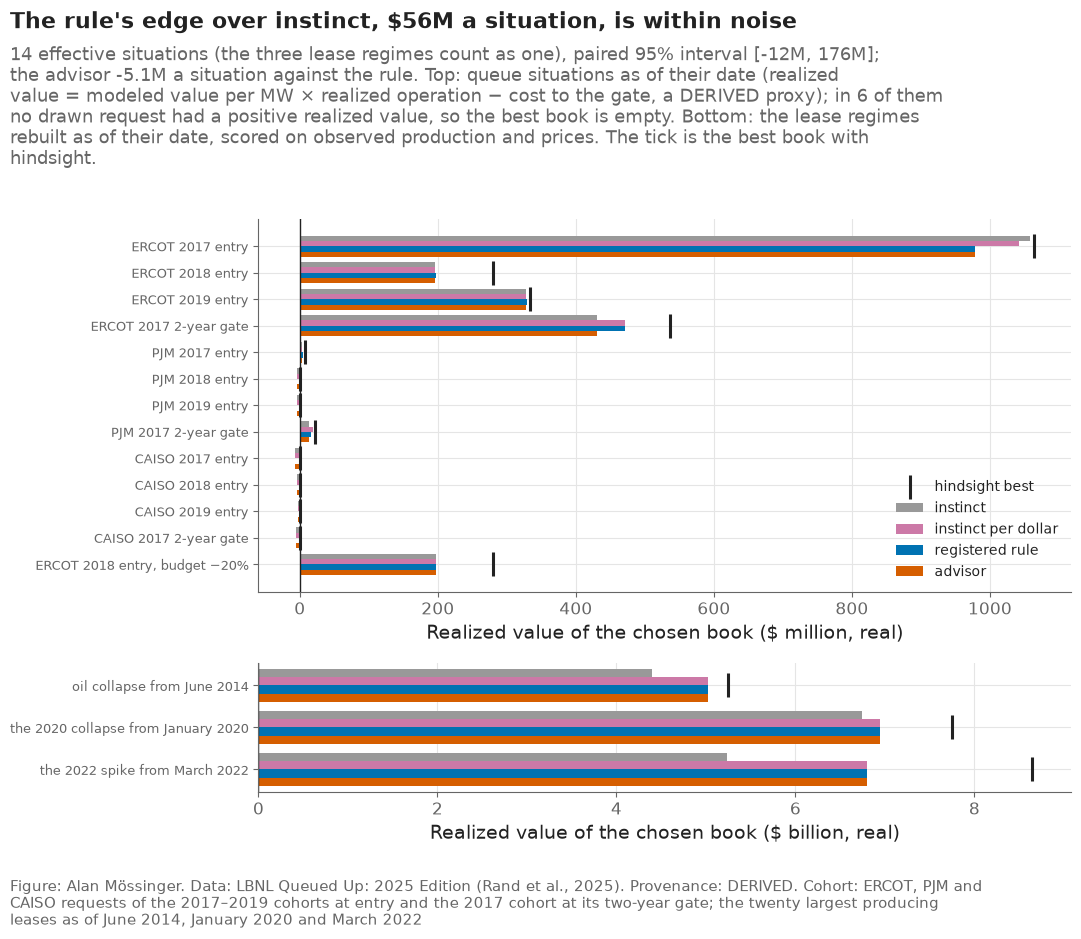

In [10]:
queue_names = [s["name"] for s in situations if s["kind"] == "queue"]
lease_names = [s["name"] for s in situations if s["kind"] == "lease"]
fig, axes = plt.subplots(2, 1, figsize=(11, 9.5), gridspec_kw={"height_ratios": [len(queue_names), len(lease_names) + 1.5]})
actors = [a for a in ("instinct", "instinct per dollar", "optimizer", "advisor", "human") if a in set(gym_scores["actor"])]
colors = {"instinct": "#999999", "instinct per dollar": "#CC79A7", "optimizer": "#0072B2", "advisor": "#D55E00", "human": "#009E73"}
height = 0.8 / len(actors)
for ax, names, unit in ((axes[0], queue_names, 1.0), (axes[1], lease_names, 1000.0)):
    y = np.arange(len(names))
    for k, actor in enumerate(actors):
        part = gym_scores[gym_scores["actor"] == actor].set_index("situation").reindex(names)
        ax.barh(y + (k - (len(actors) - 1) / 2) * height, part["realized_$M"].fillna(0) / unit, height=height, color=colors[actor], label={"optimizer": "registered rule"}.get(actor, actor))
    best = gym_scores[gym_scores["actor"] == "hindsight"].set_index("situation").reindex(names)["realized_$M"] / unit
    ax.scatter(best, y, marker="|", s=300, color=plots.INK, label="hindsight best", zorder=3)
    ax.set_yticks(y, names, fontsize=9.5)
    ax.invert_yaxis()
    ax.axvline(0, color=plots.INK, lw=1)
axes[0].set_xlabel("Realized value of the chosen book ($ million, real)")
axes[1].set_xlabel("Realized value of the chosen book ($ billion, real)")
axes[0].legend(loc="lower right", fontsize=10)  # the empty CAISO rows, clear of the bars
v = gym_v8.set_index("comparison")
ri = v.loc["optimizer minus instinct"]
noise = ri["low_$M"] <= 0 <= ri["high_$M"]
n_zero = int((sit_table["hindsight_best_$M"] <= 0).sum())
adv_line = (f"; the advisor {v.loc['advisor minus optimizer', 'mean_$M']:+,.1f}M a situation against the rule" if "advisor minus optimizer" in v.index else "; the advisor is not yet scored")
plots.finish(fig, f"The rule's edge over instinct, \${ri['mean_$M']:,.0f}M a situation, is {'within noise' if noise else 'clear of noise'}",
             f"{int(ri['situations'])} effective situations (the three lease regimes count as one), paired 95% interval [{ri['low_$M']:,.0f}M, {ri['high_$M']:,.0f}M]{adv_line}. Top: queue situations as of their date (realized value = modeled value per MW × realized operation − cost to the gate, a DERIVED proxy); in {n_zero} of them no drawn request had a positive realized value, so the best book is empty. Bottom: the lease regimes rebuilt as of their date, scored on observed production and prices. The tick is the best book with hindsight.",
             "ERCOT, PJM and CAISO requests of the 2017–2019 cohorts at entry and the 2017 cohort at its two-year gate; the twenty largest producing leases as of June 2014, January 2020 and March 2022",
             lbnl=True, sources=[config.SOURCE_BSEE, config.SOURCE_EIA_PRICES], provenance="DERIVED")
plots.save_fig(fig, "F34_decision_gym", "The decision gym: realized value of instinct, the registered rule, the advisor and the human in sixteen past situations, against hindsight.", NOTEBOOK)
plt.show()


**Reading this.** The gym asks whether a book chosen with the information of the day was worth more than instinct's once the outcomes came in. Counted as fourteen effective situations, with the three lease regimes as one (post-registration, v8), the registered rule beats instinct (top-N NPV) by $56 million a situation, but the paired interval runs from −$12 million to +$176 million, so the edge is within noise; the rule is better in 13 situations and worse in one (ERCOT 2017 entry, −$81 million). Most of its edge is in the lease regimes (+$629 million, +$206 million and +$1,556 million), where a budget-bound MILP beats a greedy ranking; in the queue rooms it gains a few million by not paying gate costs on requests that never operated. Against instinct per dollar, the analyst who knows the budget binds, the rule is level (−$2.7 million [−$12.7 million, +$3.0 million]). Doing nothing trails the rule by $604 million a situation [$67 million, $1,567 million], though it beats instinct in six of the sixteen rooms, where instinct lost money. The advisor trails the rule by $5.1 million a situation [−$11.0 million, −$1.5 million], worse in 12 of 14, and its edge over instinct (+$51 million [−$17 million, +$171 million]) is the rule's, slightly smaller. For a committee: in these rooms the AI picks good books but not better ones than a per-dollar rule, and it adds no measurable value. The sixteen-room summary above is kept for comparison with v7; the effective-situation table is the one the report cites. The human's bar appears as the dashboard's ledger fills.

## 5. The forward view: the book at 1, 2, 3, 5, 10 and 20 years

What does the owner hold at each horizon? For the leases, the incremental cash flows against the Arps baseline within the horizon (the workover is paid in month zero, the uplift starts after the lead time, so the first years are negative). For the requests, the cost to carry, the capital at the operation year and the operating margin up to the horizon, weighted by the queue models' probability of operating by each year, and nothing beyond the plant's life; a request that has not operated by the horizon is worth its carry cost, lost. The deterministic book at each horizon maximises this within-horizon value under the registered budget and cap; its full-life risk is then read off the held-out scenarios, and the advisor is asked to propose and explain the book at each horizon from the horizon table.

In [11]:
upstream_c = decision_date.lease_history_on(upstream)  # the months BSEE had published on the decision date
upstream_c = upstream_c[upstream_c["lease_number"].isin([p.split("|")[1] for p in cand.loc[cand["sector"] == "offshore oil and gas", "project_id"]])]
oil_c = upstream_c.pivot(index="lease_number", columns="month", values="oil_bbl").fillna(0)
gas_c = upstream_c.pivot(index="lease_number", columns="month", values="gas_mcf").fillna(0)
baselines = {lid: decision_date.lease_baseline_on(oil_c.loc[lid].to_numpy(), gas_c.loc[lid].to_numpy(), months=240)[:2] for lid in oil_c.index}
P_COLS = [f"p_op_{h}" for h in range(1, 8)]
curves = {r["project_id"]: r[P_COLS].to_numpy(float) for _, r in cand[cand["sector"] == "ERCOT power"].iterrows()}  # from 1 January 2025 (notebook 07)
settings = pd.read_csv(R / "scenario_settings.csv").iloc[0]
wti_flat, hh_flat = np.full(240, settings["base_wti"]), np.full(240, settings["base_hh"])
view = hz.horizon_view(cand, baselines, wti_flat, hh_flat, curves)
view.to_csv(R / "horizon_view.csv", index=False)
groups = cand.set_index("project_id")["technology"].reindex(ids).to_numpy()
hbooks = hz.horizon_books(view, capex.reindex(ids), groups, BUDGET, CAP)
hrows = []
for h, x in hbooks.items():
    xv = x.to_numpy(int)
    total = A_copula @ xv
    within = view[view["horizon_years"] == h].set_index("project_id")["expected_npv_within_horizon"].reindex(ids).to_numpy() @ xv
    hrows.append({"horizon_years": h, "n_members": int(xv.sum()), "capex_$B": float(capex.reindex(ids).to_numpy() @ xv) / 1e9, "expected_npv_within_horizon_$B": within / 1e9,
                  "full_life_expected_npv_oos_$B": total.mean() / 1e9, "full_life_cvar95_loss_oos_$B": opt.cvar(-total, LEVEL) / 1e9, "full_life_p_negative_oos": float((total < 0).mean()),
                  "jaccard_to_D": opt.jaccard(xv, x_D), "n_leases": int(xv[cand["sector"].to_numpy() == "offshore oil and gas"].sum()),
                  "n_requests": int(xv[cand["sector"].to_numpy() != "offshore oil and gas"].sum()), "members": ";".join(np.array(ids)[xv == 1])})
horizon_books = pd.DataFrame(hrows)
by_sector = view.groupby(["horizon_years", "sector"])["expected_npv_within_horizon"].sum().unstack() / 1e9
print(f"within-horizon expected NPV of all forty ($B): leases {by_sector['offshore oil and gas'].round(1).tolist()}, requests {by_sector['ERCOT power'].round(2).tolist()} at 1, 2, 3, 5, 10, 20 years")
horizon_books.drop(columns="members").round(3)


within-horizon expected NPV of all forty ($B): leases [-1.4, -1.4, 0.0, 2.3, 5.7, 8.2], requests [-1.16, -1.95, -2.54, -3.23, -2.78, -1.72] at 1, 2, 3, 5, 10, 20 years


,horizon_years,n_members,capex_$B,expected_npv_within_horizon_$B,full_life_expected_npv_oos_$B,full_life_cvar95_loss_oos_$B,full_life_p_negative_oos,jaccard_to_D,n_leases,n_requests
0,1,0,0.000,0.000,0.000,0.000,0.0,0.000,0,0
1,2,0,0.000,0.000,0.000,0.000,0.0,0.000,0,0
2,3,11,0.528,0.348,5.975,-1.926,0.0,0.579,11,0
3,5,14,0.888,2.118,7.486,-2.216,0.0,0.737,14,0
4,10,14,0.888,4.983,7.486,-2.216,0.0,0.737,14,0
5,20,14,0.888,7.089,7.486,-2.216,0.0,0.737,14,0


In [12]:
horizon_rows = []
for _, hb in horizon_books.iterrows():
    h = int(hb["horizon_years"])
    vh = view[view["horizon_years"] == h].merge(cand[["project_id", "capex", "data_completeness"]], on="project_id")
    vh = pd.DataFrame({"project_id": vh["project_id"], "technology": vh["technology"], "capex_$M": vh["capex"] / 1e6, f"expected_npv_within_{h}y_$M": vh["expected_npv_within_horizon"] / 1e6,
                       f"p_operation_by_{h}y": vh["p_operation_by_horizon"], "data_completeness": vh["data_completeness"], "in_deterministic_book": vh["project_id"].isin(hb["members"].split(";"))})
    ctx = adv.format_table(vh, f"The forty candidates within {h} years", "FORECAST; lease costs ASSUMED", note="$ million, 2024 dollars; the deterministic book maximises the within-horizon value under the budget and the cap.") + "\n" + \
          adv.format_table(horizon_books.drop(columns="members").assign(members_n=horizon_books["n_members"]), "The deterministic book at each horizon and its full-life risk out of sample", "FORECAST")
    user = adv.render("recommend", scenario=f"forward {h} years", scenario_description=f"Value counted within {h} years from the valuation date; a request that has not operated by then is worth its carry cost, lost.",
                      budget=f"${BUDGET / 1e9:.2f}B", technology_cap=f"{CAP:.0%}", revenue_case=CASE)
    out = advisor.ask(SYSTEM_BASE + "\nDATA\n\n" + ctx, user, "forward", f"{h}y")
    row = {"scenario": f"forward {h}y", "status": "not recorded" if out is None else ("replayed" if out["replayed"] else "live")}
    if out is not None:
        j = adv.parse_json(out["response"]) or {}
        members = [m for m in j.get("members", []) if m in ids]
        xh = hbooks[h].to_numpy(int)
        row.update({"book": j.get("book"), "n_members": len(members), "jaccard_to_D": jaccard_to(members, x_D), "jaccard_to_horizon_book": jaccard_to(members, xh),
                    "cited_expected_npv_$B": j.get("expected_npv_usd_billion"), "cited_tail_$B": j.get("tail_usd_billion"), "binding_constraint": j.get("binding_constraint"),
                    "weakest_provenance": j.get("weakest_provenance"), "grounding_rate": out["verification"]["rate"], "n_numbers": out["verification"]["n_numbers"],
                    "ungrounded": ";".join(out["verification"]["ungrounded"]), "why": j.get("why"), "what_would_change_the_answer": j.get("what_would_change_the_answer"),
                    "model": out["model"], "members": ";".join(members)})
    horizon_rows.append(row)
recommendations = pd.concat([recommendations, pd.DataFrame(horizon_rows)], ignore_index=True)
recommendations.to_csv(R / "advisor_recommendations.csv", index=False)
horizon_books["advisor_status"] = [r["status"] for r in horizon_rows]
horizon_books.to_csv(R / "horizon_books.csv", index=False)
recommendations[["scenario", "status"] + [c for c in ("book", "n_members", "jaccard_to_D", "grounding_rate", "binding_constraint") if c in recommendations.columns]]


,scenario,status,book,n_members,jaccard_to_D,grounding_rate,binding_constraint
0,base,live,C deterministic MILP,19,0.809524,1.000000,budget
1,oil collapse (2020 path),live,D risk-aware MILP,19,1.000000,0.947368,nothing binds
2,"high gas, low spark spread",live,D risk-aware MILP,19,1.000000,0.950000,budget
3,weak wind year,live,D risk-aware MILP,19,1.000000,0.947368,technology cap
4,solar curtailment,live,D risk-aware MILP,19,1.000000,0.944444,nothing binds
5,two-year delay,live,D risk-aware MILP,19,1.000000,1.000000,technology cap
6,simultaneous downside,live,custom,14,0.736842,0.705882,technology cap
7,forward 1y,live,custom,0,0.000000,1.000000,nothing binds
8,forward 2y,live,custom,0,0.000000,1.000000,nothing binds
9,forward 3y,live,deterministic book (3-year horizon),11,0.578947,1.000000,nothing binds


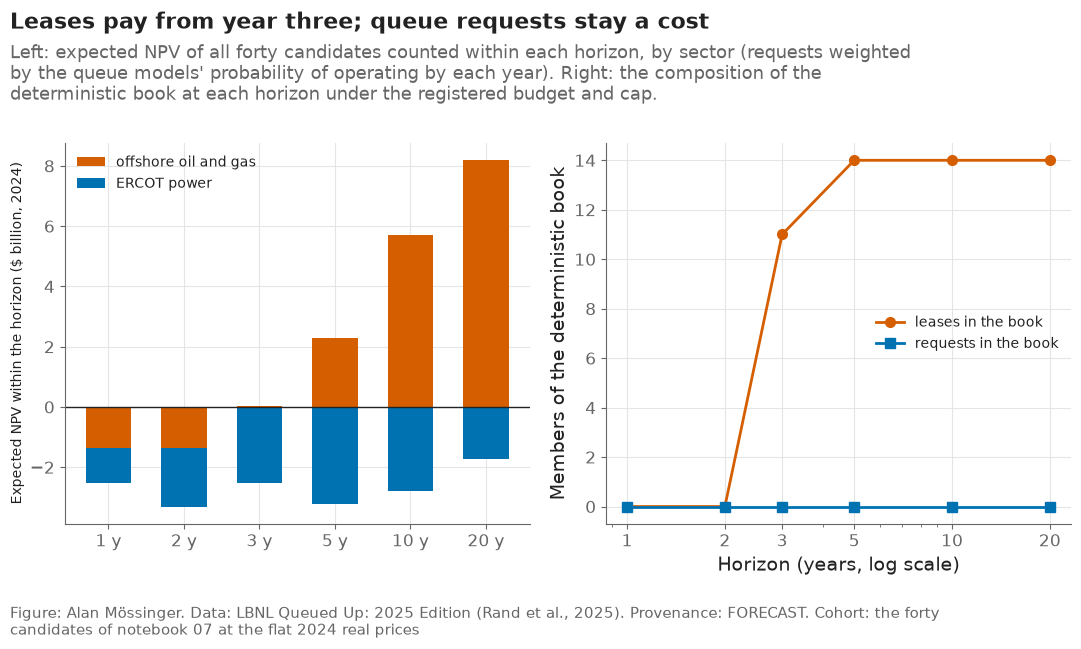

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
sector_color = {"offshore oil and gas": "#D55E00", "ERCOT power": "#0072B2"}
H = list(hz.HORIZONS)
xpos = np.arange(len(H))
bottom_pos, bottom_neg = np.zeros(len(H)), np.zeros(len(H))
for sector in ("offshore oil and gas", "ERCOT power"):
    vals = by_sector[sector].reindex(H).to_numpy()
    base_ = np.where(vals >= 0, bottom_pos, bottom_neg)
    axes[0].bar(xpos, vals, bottom=base_, color=sector_color[sector], label=sector, width=0.6)
    bottom_pos += np.where(vals >= 0, vals, 0)
    bottom_neg += np.where(vals < 0, vals, 0)
axes[0].axhline(0, color=plots.INK, lw=1)
axes[0].set_xticks(xpos, [f"{h} y" for h in H])
axes[0].set_ylabel("Expected NPV within the horizon ($ billion, 2024)")
axes[0].legend(loc="upper left", fontsize=10)
axes[1].plot(H, horizon_books["n_leases"], marker="o", lw=2, color="#D55E00", label="leases in the book")
axes[1].plot(H, horizon_books["n_requests"], marker="s", lw=2, color="#0072B2", label="requests in the book")
axes[1].set_xscale("log")
axes[1].set_xticks(H, [str(h) for h in H])
axes[1].set_xlabel("Horizon (years, log scale)")
axes[1].set_ylabel("Members of the deterministic book")
axes[1].yaxis.set_major_locator(plt.MaxNLocator(integer=True))  # members are counts
axes[1].legend(loc="center right", fontsize=10)
first_pos = next((h for h in H if by_sector.loc[h, "offshore oil and gas"] > 0), None)
plots.finish(fig, ((f"The lease book turns positive within {first_pos} years; the requests are a cost at every horizon, \${-by_sector.loc[20, 'ERCOT power']:.2f}B of expected loss by year 20" if by_sector.loc[20, 'ERCOT power'] < 0
                    else f"The lease book turns positive within {first_pos} years; the requests reach \${by_sector.loc[20, 'ERCOT power']:.2f}B by year 20")
                   if first_pos else "No horizon shows a positive lease book"),
             "Left: expected NPV of all forty candidates counted within each horizon, by sector (requests weighted by the queue models' probability of operating by each year). Right: the composition of the deterministic book at each horizon under the registered budget and cap.",
             "the forty candidates of notebook 07 at the flat 2024 real prices", lbnl=True, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F35_horizon_view", "The forward view: expected NPV within 1, 2, 3, 5, 10 and 20 years by sector, and the book at each horizon.", NOTEBOOK)
plt.show()


**Reading this.** The horizon view answers "when". Counted within each horizon, the twenty leases are worth −$1.4 billion at one and two years (the workovers are paid, the uplift has not started), break even at three ($0.0 billion) and reach $2.3, $5.7 and $8.2 billion at five, ten and twenty years. The twenty requests are a cost at every horizon: −$1.16 billion at one year, deepest at five (−$3.23 billion) and still −$1.72 billion at twenty, because most never operate and the few that do have not paid back on the flat 2024 path. So the best book holds nothing at one and two years, eleven leases at three, and fourteen leases and no request from five years on; its value within twenty years is $7.09 billion, and its full-life value on the held-out scenarios $7.49 billion with a $2.22 billion tail profit. No horizon buys a request on the flat path, where part D, on scenario values with prices reverting upward, holds requests beside the leases. The advisor proposes the horizon books themselves (0, 0, 11, 14, 14 and 14 members) and grounds every number.

## 6. Evaluation of the AI outputs, and the ledger

The checklist asks that AI outputs be evaluated, not admired: the number-grounding rate over every recorded answer, agreement with the optimizer, the gym score against instinct, and a rubric on up to ten answers. The rubric's mechanical items are filled by code (names a book, cites at least three grounded numbers, states what would change the answer, names the weakest provenance); the `human_label` column is empty for the author's own reading. The advisor's base-case recommendation, when recorded, is appended to the decision ledger as an entry of actor "advisor".

In [14]:
recorded = [r for r in advisor.records.values() if not str(r.get("mode", "")).startswith("challenge-")]  # the challenger's calls are scored in notebook 11 under their own registered checks
grounding = pd.Series([r["verification"]["rate"] for r in recorded], dtype=float)
rec_ok = recommendations[recommendations["status"] != "not recorded"]
gym_adv = gym_scores[gym_scores["actor"] == "advisor"]
gym_opt = gym_scores[gym_scores["actor"] == "optimizer"]
evaluation = pd.DataFrame([
    {"metric": "calls this run (replayed / live / missing)", "value": f"{advisor.calls['replayed']} / {advisor.calls['live']} / {advisor.calls['missing']}"},
    {"metric": "recorded answers in advisor_runs.jsonl", "value": len(recorded)},
    {"metric": "mean number-grounding rate over recorded answers", "value": round(float(grounding.mean()), 3) if len(grounding) else "no record"},
    {"metric": "answers with every number grounded (share)", "value": round(float((grounding == 1).mean()), 3) if len(grounding) else "no record"},
    {"metric": "scenario recommendations recorded (of 7 stresses + 6 horizons)", "value": f"{len(rec_ok)} of {len(recommendations)}"},
    {"metric": "mean Jaccard of recommended members to book D (stresses)", "value": round(float(rec_ok[rec_ok['scenario'].isin(stresses['stress'])]['jaccard_to_D'].mean()), 3) if len(rec_ok) else "no record"},
    {"metric": "share naming book D (stresses)", "value": round(float(rec_ok[rec_ok['scenario'].isin(stresses['stress'])]['agrees_with_D_by_name'].mean()), 3) if len(rec_ok) and "agrees_with_D_by_name" in rec_ok else "no record"},
    {"metric": "gym: advisor minus instinct, mean $M (situations recorded)", "value": f"{gym_adv['vs_instinct_$M'].mean():+,.1f} ({len(gym_adv)})" if len(gym_adv) else "no record"},
    {"metric": "gym: optimizer minus instinct, mean $M", "value": f"{gym_opt['vs_instinct_$M'].mean():+,.1f} ({len(gym_opt)})"},
    {"metric": "gym: advisor wins against instinct (situations)", "value": int((gym_adv["vs_instinct_$M"] > 0).sum()) if len(gym_adv) else "no record"},
    {"metric": "gym: mean regret against hindsight, instinct / optimizer / advisor ($M)",
     "value": f"{gym_scores[gym_scores['actor'] == 'instinct']['regret_$M'].mean():,.1f} / {gym_opt['regret_$M'].mean():,.1f} / " + (f"{gym_adv['regret_$M'].mean():,.1f}" if len(gym_adv) else "no record")},
    {"metric": "challenge calls recorded (of 6: questions, check and opposing case for two statements)", "value": int((challenges["status"] != "not recorded").sum())},
    {"metric": "model", "value": advisor.model},
])
evaluation.to_csv(R / "advisor_evaluation.csv", index=False)
rubric_rows = []
for r in [r for r in recorded if r["mode"] in ("recommend", "gym", "forward")][:10]:  # the JSON answers; the challenge rounds are prose and are read in their transcripts
    j = adv.parse_json(r["response"]) or {}
    rubric_rows.append({"tag": f"{r['mode']}:{r['tag']}", "names_a_book": bool(j.get("book") or j.get("members")), "cites_three_grounded_numbers": r["verification"]["n_grounded"] >= 3,
                        "every_number_grounded": r["verification"]["rate"] == 1.0, "states_what_would_change": bool(j.get("what_would_change_the_answer") or j.get("what_i_rejected_and_why")),
                        "names_weakest_provenance": j.get("weakest_provenance") in config.PROVENANCE, "human_label": ""})
rubric = pd.DataFrame(rubric_rows, columns=["tag", "names_a_book", "cites_three_grounded_numbers", "every_number_grounded", "states_what_would_change", "names_weakest_provenance", "human_label"])
rubric.to_csv(R / "advisor_rubric.csv", index=False)
base_rec = recommendations[recommendations["scenario"] == "base"].iloc[0]
if base_rec["status"] != "not recorded":
    kept = pd.read_csv(R / "decision_ledger.csv")
    kept[kept["entry_id"] != "NB10-advisor-base"].to_csv(R / "decision_ledger.csv", index=False)  # replaced on every run, so the row matches this run's tables (a v7 row survived the v8 rerun; decision #93)
    members = [m for m in str(base_rec["members"]).split(";") if m]
    x = np.array([1 if p in members else 0 for p in ids])
    total = A_copula @ x
    adv.ledger_append({"entry_id": "NB10-advisor-base", "actor": "advisor", "mode": "forward book", "horizon": "2025–2044", "revenue_case": CASE, "budget": BUDGET, "lam": LAM,
                       "technology_cap": CAP, "members": ";".join(members), "n_members": len(members), "capex": float(capex.reindex(ids).to_numpy() @ x),
                       "expected_npv_oos": float(total.mean()), "cvar_loss_oos": opt.cvar(-total, LEVEL), "note": f"advisor, base case, {base_rec['model']}"})
    print(f"ledger: the advisor's base-case book written: {len(members)} members, ${float(capex.reindex(ids).to_numpy() @ x) / 1e9:.2f}B of stage-one charges against the ${BUDGET / 1e9:.2f}B budget")
else:
    print("ledger: the advisor's base-case book not written (not recorded)")
print(f"{time.time() - START:.0f} s")
evaluation


ledger: the advisor's base-case book written: 19 members, $2.31B of stage-one charges against the $2.31B budget
613 s


,metric,value
0,calls this run (replayed / live / missing),16 / 19 / 0
1,recorded answers in advisor_runs.jsonl,214
2,mean number-grounding rate over recorded answers,0.938
3,answers with every number grounded (share),0.589
4,scenario recommendations recorded (of 7 stresses + 6 horizons),13 of 13
5,mean Jaccard of recommended members to book D (stresses),0.935
6,share naming book D (stresses),0.714
7,"gym: advisor minus instinct, mean $M (situations recorded)",+144.4 (16)
8,"gym: optimizer minus instinct, mean $M",+148.9 (16)
9,gym: advisor wins against instinct (situations),4


### The workflow in one picture

Where the AI sits, what it may see, and where the human keeps the last word; the figure the appendix carries (`figures/F36_ai_workflow`).

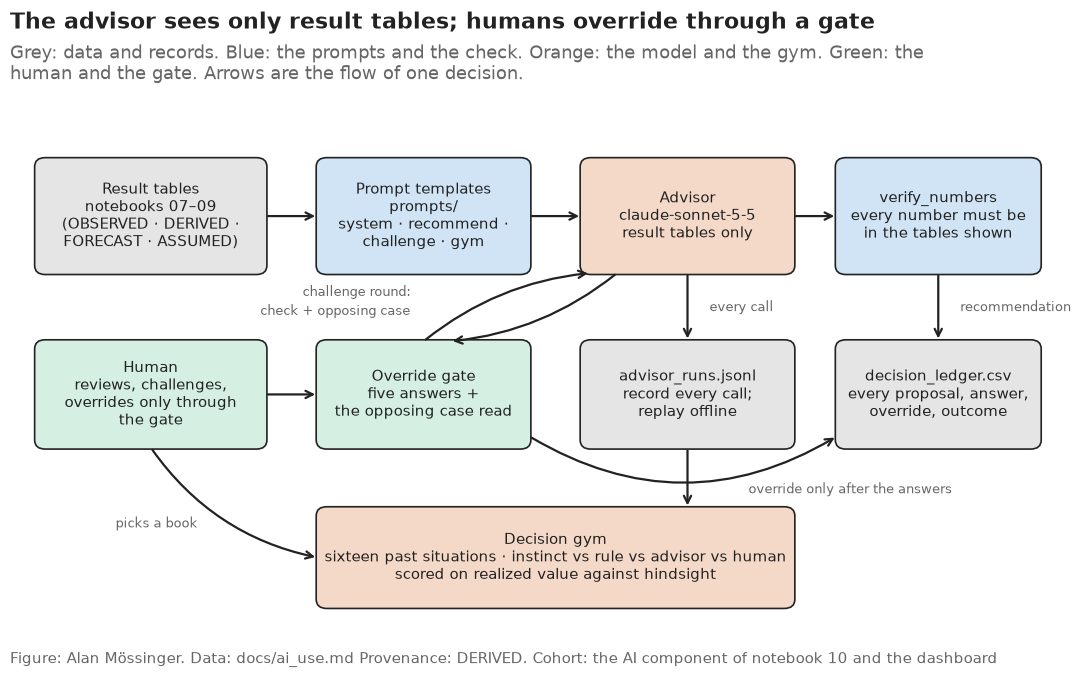

In [15]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 6.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 6.6)
ax.axis("off")
NL = chr(10)
boxes = {  # name: (x, y, w, h, color, text)
    "tables": (0.3, 4.6, 2.6, 1.5, "#E5E5E5", NL.join(["Result tables", "notebooks 07–09", "(OBSERVED · DERIVED ·", "FORECAST · ASSUMED)"])),
    "prompt": (3.5, 4.6, 2.4, 1.5, "#D0E4F5", NL.join(["Prompt templates", "prompts/", "system · recommend ·", "challenge · gym"])),
    "advisor": (6.5, 4.6, 2.4, 1.5, "#F5D9C8", NL.join(["Advisor", advisor.model, "result tables only"])),
    "verify": (9.4, 4.6, 2.3, 1.5, "#D0E4F5", NL.join(["verify_numbers", "every number must be", "in the tables shown"])),
    "human": (0.3, 2.3, 2.6, 1.4, "#D5F0E3", NL.join(["Human", "reviews, challenges,", "overrides only through", "the gate"])),
    "gate": (3.5, 2.3, 2.4, 1.4, "#D5F0E3", NL.join(["Override gate", "five answers +", "the opposing case read"])),
    "record": (6.5, 2.3, 2.4, 1.4, "#E5E5E5", NL.join(["advisor_runs.jsonl", "record every call;", "replay offline"])),
    "ledger": (9.4, 2.3, 2.3, 1.4, "#E5E5E5", NL.join(["decision_ledger.csv", "every proposal, answer,", "override, outcome"])),
    "gym": (3.5, 0.2, 5.4, 1.3, "#F5D9C8", NL.join(["Decision gym", "sixteen past situations · instinct vs rule vs advisor vs human", "scored on realized value against hindsight"])),
}
for name, (x, y, w, h, color, text) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", facecolor=color, edgecolor=plots.INK, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10.5, color=plots.INK)


def draw(start, end, rad=0.0):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.6, color=plots.INK, connectionstyle=f"arc3,rad={rad}"))


def label(x, y, text, ha="center"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=9, color=plots.MUTED)


b = boxes
draw((b["tables"][0] + 2.6, 5.35), (b["prompt"][0], 5.35))  # tables -> prompt
draw((b["prompt"][0] + 2.4, 5.35), (b["advisor"][0], 5.35))  # prompt -> advisor
draw((b["advisor"][0] + 2.4, 5.35), (b["verify"][0], 5.35))  # advisor -> verify
draw((7.7, 4.6), (7.7, 3.7))  # advisor -> record
label(7.95, 4.15, "every call", ha="left")
draw((10.55, 4.6), (10.55, 3.7))  # verify -> ledger
label(10.8, 4.15, "recommendation", ha="left")
draw((2.9, 3.0), (3.5, 3.0))  # human -> gate
draw((5.9, 2.45), (9.4, 2.45), rad=0.3)  # gate -> ledger, dipping under the record box
label(9.55, 1.75, "override only after the answers", ha="center")
draw((4.7, 3.7), (6.6, 4.6), rad=-0.15)  # gate <-> advisor: the challenge round
draw((6.9, 4.6), (5.0, 3.7), rad=-0.15)
label(4.55, 4.35, "challenge round:", ha="right")
label(4.55, 4.1, "check + opposing case", ha="right")
draw((7.7, 2.3), (7.7, 1.5))  # record -> gym (the advisor's picks)
draw((1.6, 2.3), (3.5, 0.85), rad=0.2)  # human -> gym
label(1.2, 1.3, "picks a book", ha="left")
plots.finish(fig, "The advisor sees only the result tables, every number it writes is checked, every call is recorded and replayed, and the human overrides only through the gate",
             "Grey: data and records. Blue: the prompts and the check. Orange: the model and the gym. Green: the human and the gate. Arrows are the flow of one decision.",
             "the AI component of notebook 10 and the dashboard", lbnl=False, sources=["docs/ai_use.md"], provenance="DERIVED")
plots.save_fig(fig, "F36_ai_workflow", "The AI workflow: grounding, verification, record and replay, the override gate, the ledger and the gym.", NOTEBOOK)
plt.show()


**Reading this.** The picture is the governance of the component: the only input is the tables, the only outputs are checked text and a record, and the two places where a decision is made — the ledger and the gym — are the two places where the human and the AI are scored side by side.

In [16]:
checks = pd.DataFrame([
    {"check": "every gym table hides the outcome columns", "pass": all(not set(gym.HIDDEN) & set(s["table"].columns) for s in situations)},
    {"check": "every actor's book fits its situation's budget", "pass": bool((gym_scores["cost_$M"] <= gym_scores["budget_$M"] + 1e-6).all())},
    {"check": "no actor beats hindsight", "pass": bool((gym_scores["regret_$M"] >= -1e-6).all())},
    {"check": "every horizon book fits the budget and the cap", "pass": all(capex.reindex(ids).to_numpy() @ x.to_numpy() <= BUDGET + 1e-6 for x in hbooks.values())},
    {"check": "every recorded answer carries a verification", "pass": all("verification" in r for r in recorded)},
    {"check": "the notebook ran without a key or with one, and says which", "pass": True, "note": "live" if advisor.live else "replay"},
])
checks.to_csv(R / "advisor_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"all {len(checks)} checks pass; {time.time() - START:.0f} s")
checks


all 6 checks pass; 614 s


,check,pass,note
0,every gym table hides the outcome columns,True,NaN
1,every actor's book fits its situation's budget,True,NaN
2,no actor beats hindsight,True,NaN
3,every horizon book fits the budget and the cap,True,NaN
4,every recorded answer carries a verification,True,NaN
5,"the notebook ran without a key or with one, and says which",True,live


## 7. The project in one picture

The report opens with this diagram: the four asset classes the budget is split across, the queue engine of Part I that times the power candidates, the five steps, and the decision they produce. Every number on it is read from the result tables.

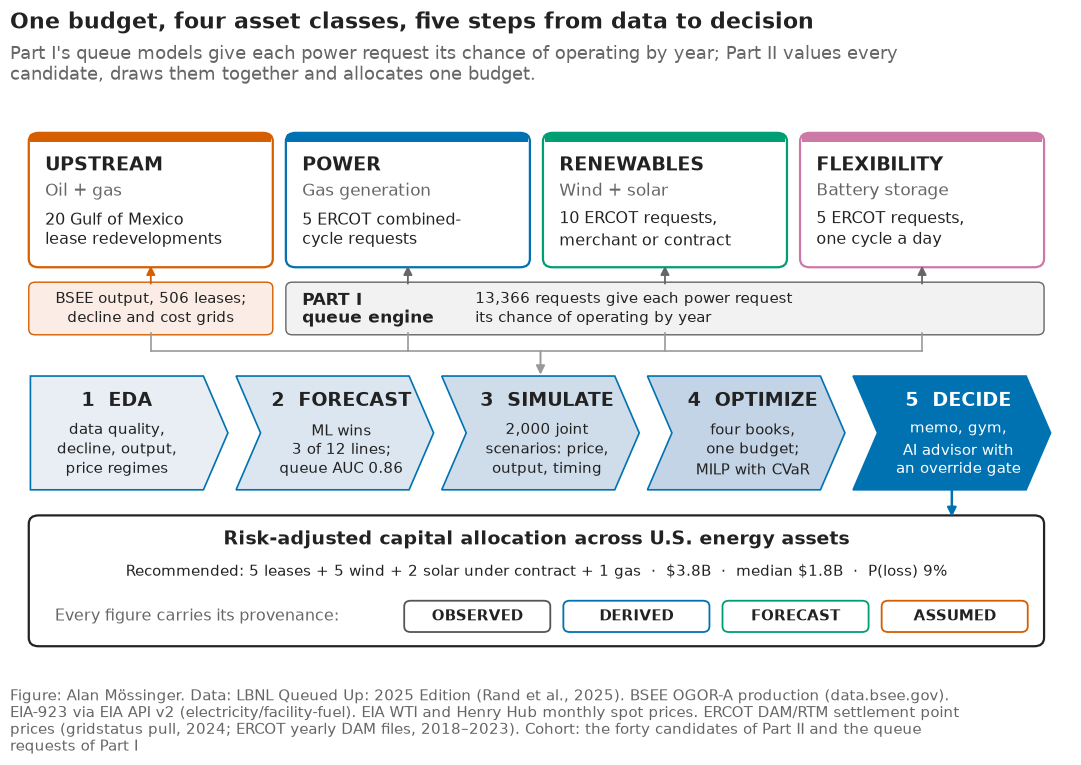

In [17]:
from matplotlib.patches import FancyBboxPatch, Polygon

NL = chr(10)
counts = pd.read_csv(R / "trackA_event_counts.csv").set_index("region")
metrics_q = pd.read_csv(R / "metrics.csv")
auc3 = metrics_q[(metrics_q["track"] == "A") & (metrics_q["model"] == "dt_lgbm") & (metrics_q["metric"] == "auc") & (metrics_q["horizon"] == 3)]["estimate"].iloc[0]
c20 = pd.read_csv(R / "success_criteria_v6_scored.csv")
c20 = c20[c20["registered"]]
inv_pool = pd.read_csv(R / "investment_candidates.csv")
n_leases_pool = int((inv_pool["sector"] == "offshore oil and gas").sum())
n_tech = cand[cand["sector"] == "ERCOT power"]["technology"].value_counts()
settings0 = pd.read_csv(R / "scenario_settings.csv").iloc[0]
bc = pd.read_csv(R / "posthoc_books_committee.csv").set_index("book").loc["D risk-aware MILP"]
bc_tech = cand.set_index("project_id").loc[bc["members"].split(";"), "technology"].value_counts()
lease_val = pd.read_csv(R / "posthoc_lease_values.csv")

INK2, MUTED2 = plots.INK, plots.MUTED
SECTOR = {"UPSTREAM": "#D55E00", "POWER": "#0072B2", "RENEWABLES": "#009E73", "FLEXIBILITY": "#CC79A7"}
fig, ax = plt.subplots(figsize=(11, 7.7))  # the project's 11-inch width, so type is not shrunk when printed
ax.set_xlim(0, 13)
ax.set_ylim(0, 7.45)
ax.axis("off")


def box(x, y, w, h, edge, fill="#FFFFFF", lw=1.6, radius=0.12):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0.02,rounding_size={radius}", facecolor=fill, edgecolor=edge, lw=lw))


def arrow(x0_, y0_, x1_, y1_, color, lw=1.6):
    ax.annotate("", xy=(x1_, y1_), xytext=(x0_, y0_), arrowprops=dict(arrowstyle="-|>", lw=lw, color=color, shrinkA=0, shrinkB=0))


# row 1: the four asset classes one budget is split across
cards = [
    ("UPSTREAM", "Oil + gas", NL.join([f"{len(lease_val)} Gulf of Mexico", "lease redevelopments"])),
    ("POWER", "Gas generation", NL.join([f"{n_tech.get('Gas CC', 0)} ERCOT combined-", "cycle requests"])),
    ("RENEWABLES", "Wind + solar", NL.join([f"{n_tech.get('Wind', 0) + n_tech.get('Solar', 0)} ERCOT requests,", "merchant or contract"])),
    ("FLEXIBILITY", "Battery storage", NL.join([f"{n_tech.get('Storage', 0)} ERCOT requests,", "one cycle a day"])),
]
W, GAP, X0, Y1, H1 = 2.95, 0.2, 0.25, 5.45, 1.85
xs = [X0 + i * (W + GAP) for i in range(4)]
for (head, sub, body), x in zip(cards, xs):
    box(x, Y1, W, H1, SECTOR[head])
    ax.add_patch(FancyBboxPatch((x, Y1 + H1 - 0.11), W, 0.11, boxstyle="square,pad=0", facecolor=SECTOR[head], edgecolor="none"))
    ax.text(x + 0.18, Y1 + H1 - 0.3, head, fontsize=14, fontweight="bold", color=INK2, va="top")
    ax.text(x + 0.18, Y1 + H1 - 0.68, sub, fontsize=12, color=MUTED2, va="top")
    ax.text(x + 0.18, Y1 + H1 - 1.04, body, fontsize=11.5, color=INK2, va="top", linespacing=1.3)

# row 2: what each side rests on — the lease data and grid, and Part I's queue engine for the three power classes
YB, HB = 4.5, 0.7
box(xs[0], YB, W, HB, SECTOR["UPSTREAM"], fill="#FBEDE5", lw=1.0, radius=0.08)
ax.text(xs[0] + W / 2, YB + HB / 2, NL.join([f"BSEE output, {n_leases_pool} leases;", "decline and cost grids"]),
        fontsize=11, color=INK2, ha="center", va="center", linespacing=1.25)
arrow(xs[0] + W / 2, YB + HB, xs[0] + W / 2, Y1, SECTOR["UPSTREAM"], lw=1.3)
xq, wq = xs[1], xs[3] + W - xs[1]
box(xq, YB, wq, HB, "#666666", fill="#F2F2F2", lw=1.0, radius=0.08)
ax.text(xq + 0.18, YB + HB / 2, NL.join(["PART I", "queue engine"]), fontsize=12, linespacing=1.15, fontweight="bold", color=INK2, va="center")
ax.text(xq + 2.3, YB + HB / 2,  # clear of the bold "queue engine"
        NL.join([f"{int(counts.loc['All', 'All']):,} requests give each power request", "its chance of operating by year"]),
        fontsize=11, color=INK2, va="center", linespacing=1.25)
for x in xs[1:]:
    arrow(x + W / 2, YB + HB, x + W / 2, Y1, "#666666", lw=1.3)

# a bracket gathering everything into the five steps
yb = 4.25
ax.plot([X0 + W / 2, xs[3] + W / 2], [yb, yb], color="#999999", lw=1.2)
for x in xs:
    ax.plot([x + W / 2, x + W / 2], [YB, yb], color="#999999", lw=1.2)
arrow(6.5, yb, 6.5, 3.92, "#999999", lw=1.4)

# row 3: the five steps
steps = [
    ("EDA", NL.join(["data quality,", "decline, output,", "price regimes"])),
    ("FORECAST", NL.join(["ML wins", f"{int((c20['result'] == 'PASS').sum())} of {len(c20)} lines;", f"queue AUC {auc3:.2f}"])),
    ("SIMULATE", NL.join([f"{int(settings0['n_scenarios']):,} joint", "scenarios: price,", "output, timing"])),
    ("OPTIMIZE", NL.join(["four books,", "one budget;", "MILP with CVaR"])),
    ("DECIDE", NL.join(["memo, gym,", "AI advisor with", "an override gate"])),
]
w, h, y0, tip = 2.42, 1.6, 2.3, 0.3
shades = ["#E8EEF4", "#DCE6F0", "#CFDDEB", "#C3D4E6", "#0072B2"]
for i, (head, body) in enumerate(steps):
    xa = X0 + i * (w + 0.1)
    pts = [(xa, y0), (xa + w - tip, y0), (xa + w, y0 + h / 2), (xa + w - tip, y0 + h), (xa, y0 + h)]
    if i > 0:
        pts.append((xa + tip, y0 + h / 2))
    ax.add_patch(Polygon(pts, closed=True, facecolor=shades[i], edgecolor="#0072B2", lw=1.2))
    tc = "#FFFFFF" if i == 4 else INK2
    cx = xa + (w + (tip if i else 0) - tip) / 2 + (0.08 if i else 0)
    ax.text(cx, y0 + h - 0.22, f"{i + 1}  {head}", fontsize=13.5, fontweight="bold", color=tc, ha="center", va="top")
    ax.text(cx, y0 + h - 0.62, body, fontsize=10.8, color=tc, ha="center", va="top", linespacing=1.3)

# row 4: the decision
arrow(X0 + 4 * (w + 0.1) + w / 2, y0, X0 + 4 * (w + 0.1) + w / 2, 1.92, "#0072B2", lw=1.8)
box(X0, 0.12, 12.4, 1.8, INK2)
ax.text(6.45, 1.74, "Risk-adjusted capital allocation across U.S. energy assets", fontsize=14, fontweight="bold", color=INK2, ha="center", va="top")
renewables = [f"{bc_tech[t]} {label}" for t, label in (("Wind", "wind"), ("Solar", "solar")) if bc_tech.get(t, 0)]
book_parts = ([f"{bc_tech.get('Lease redevelopment', 0)} leases"] + ([" + ".join(renewables) + " under contract"] if renewables else [])
              + [f"{bc_tech[t]} {label}" for t, label in (("Gas CC", "gas"), ("Storage", "storage")) if bc_tech.get(t, 0)])  # every technology the book holds (decision #93)
book_line = f"Recommended: {' + '.join(book_parts)}  ·  ${bc['capex'] / 1e9:.1f}B  ·  median ${bc['median'] / 1e9:.1f}B  ·  P(loss) {bc['p_negative']:.0%}"
ax.text(6.45, 1.26, book_line, fontsize=11, color=INK2, ha="center", va="top", parse_math=False)
ax.text(0.55, 0.52, "Every figure carries its provenance:", fontsize=11.5, color=MUTED2, ha="left", va="center")
for j, (lab, col) in enumerate([("OBSERVED", "#555555"), ("DERIVED", "#0072B2"), ("FORECAST", "#009E73"), ("ASSUMED", "#D55E00")]):
    xl = 4.85 + j * 1.95
    box(xl, 0.32, 1.75, 0.4, col, lw=1.3, radius=0.08)
    ax.text(xl + 0.875, 0.52, lab, fontsize=11, fontweight="bold", color=INK2, ha="center", va="center")
plots.finish(fig, "One budget, four asset classes, five steps from data to decision",
             "Part I's queue models give each power request its chance of operating by year; Part II values every candidate, draws them together and allocates one budget.",
             "the forty candidates of Part II and the queue requests of Part I", lbnl=False,
             sources=["LBNL Queued Up: 2025 Edition (Rand et al., 2025).", config.SOURCE_BSEE, config.SOURCE_EIA923, config.SOURCE_EIA_PRICES, config.SOURCE_ERCOT])
plots.save_fig(fig, "F0_overview", "The project in one picture: four asset classes, the queue engine, the five steps and the decision they produce.", NOTEBOOK)
plt.show()


**Reading this.** The diagram is the report's table of contents in one image: the top row is what can be bought, the chevrons are the work, the bottom box is the answer. The grey card on the left is the part a portfolio study usually leaves out — whether a planned plant is ever built — and it is the link between the two halves of the report. The bottom line is the committee-grid book D of notebook 09 part E, with every technology it holds: 6 leases, 5 wind and 1 solar request under contract and 1 gas request, $3.3 billion of stage-one charges, a median of $1.5 billion and a 10% chance of a loss.

## Takeaways

- The advisor is a function of the result tables and nothing else (13,139 characters and 200 numbers in the base case); the grounding check counts every number it writes, and the record of 214 calls in `results/advisor_runs.jsonl` replays every answer offline. Mean grounding is 0.938, and 59% of answers ground every number.
- Its recommendations follow the optimizer's books: D in five of seven scenarios, C in the base case, a book of its own in the simultaneous downside (mean Jaccard to D 0.935). In the challenge rounds it finds the all-leases book strongest on expected value but outside the cap and converges on D with its gas request re-scored; for the renewables-only statement it converges on the lease core plus the contracted wind requests.
- The two reasoning prompts are the override gate: the dashboard refuses an override until the five questions are answered and the opposing case has been read, and the ledger keeps the answers with the decision.
- The gym (post-registration, fourteen effective situations): the rule's edge over instinct is $56 million a situation, within noise [−12, +176]; instinct per dollar is level with the rule; the advisor trails the rule by $5.1 million a situation [−11.0, −1.5]. In these rooms the AI adds no measurable value over a per-dollar rule.
- The forward view says when: the lease book breaks even at three years and reaches $8.2 billion at twenty; the requests are a cost at every horizon (−$1.72 billion at twenty), so no horizon book holds a request.
- The ledger's `NB10-advisor-base` row is rewritten on every run (decision #93): it is the advisor's base-case pick, 19 members using $2.31 billion of stage-one charges against the $2.31 billion budget.
- **What goes to the report:** F34, F35, `advisor_recommendations.csv`, `advisor_evaluation.csv`, `advisor_rubric.csv`, `decision_gym_situations.csv`, `decision_gym_scores.csv`, `horizon_view.csv`, `horizon_books.csv`, the two challenge transcripts, `prompts/`.